# Build the Marketing Mix Model

## Load the prepared data and define transformations

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

In [2]:
# Resolve the project root from the current notebook location.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "mmm_eda_clean.csv"

df = pd.read_csv(DATA_PATH, parse_dates=["DATE"])
df = df.sort_values("DATE").reset_index(drop=True)

# Media variables measured in spend.
MEDIA_COLS = [
    "tv_S",
    "ooh_S",
    "print_S",
    "facebook_S",
    "search_S",
]

TARGET = "revenue"

In [3]:
# Geometric adstock:
# current week's effect = current spend + decay * previous week's effect.
# decay must be between 0 and 1.
def geometric_adstock(x, decay=0.5):
    if not 0 <= decay < 1:
        raise ValueError("decay must be >= 0 and < 1")

    x = np.asarray(x, dtype=float)
    result = np.zeros_like(x, dtype=float)

    for t in range(len(x)):
        result[t] = x[t]
        if t > 0:
            result[t] += decay * result[t - 1]

    return result

In [4]:
# Hill saturation:
# maps non-negative input into a bounded response between 0 and 1.
# half_saturation is the input where response equals 0.5.
def hill_saturation(x, half_saturation, slope=1.0):
    if half_saturation <= 0:
        raise ValueError("half_saturation must be positive")
    if slope <= 0:
        raise ValueError("slope must be positive")

    x = np.asarray(x, dtype=float)

    if np.any(x < 0):
        raise ValueError("Hill saturation requires non-negative input")

    x_power = np.power(x, slope)
    half_power = half_saturation ** slope

    return x_power / (x_power + half_power)

In [5]:
# Basic validation before transformation.
assert df["DATE"].is_monotonic_increasing
assert df["DATE"].is_unique
assert df[MEDIA_COLS].notna().all().all()
assert (df[MEDIA_COLS] >= 0).all().all()

print("Dataset shape:", df.shape)
print("Date range:", df["DATE"].min().date(), "to", df["DATE"].max().date())
print("Media channels:", MEDIA_COLS)
print("Adstock and Hill saturation functions defined successfully.")

Dataset shape: (208, 12)
Date range: 2015-11-23 to 2019-11-11
Media channels: ['tv_S', 'ooh_S', 'print_S', 'facebook_S', 'search_S']
Adstock and Hill saturation functions defined successfully.


## Create initial transformed media features

In [6]:
DECAY_START = 0.5
HILL_SLOPE_START = 1.0

transformed_df = df[["DATE", TARGET]].copy()
transformation_summary = []

In [7]:
for channel in MEDIA_COLS:
    raw_spend = df[channel].to_numpy(dtype=float)

    # Apply geometric adstock to represent carryover.
    adstocked = geometric_adstock(raw_spend, decay=DECAY_START)

    # Use the median of positive adstocked values as a provisional
    # half-saturation point. This is a starting value, not a fitted one.
    positive_values = adstocked[adstocked > 0]

    if len(positive_values) == 0:
        raise ValueError(f"{channel} has no positive spend values")

    half_saturation = float(np.median(positive_values))

    saturated = hill_saturation(
        adstocked,
        half_saturation=half_saturation,
        slope=HILL_SLOPE_START,
    )

    transformed_df[f"{channel}_adstock"] = adstocked
    transformed_df[f"{channel}_mmm"] = saturated

    transformation_summary.append({
        "Channel": channel,
        "Raw spend mean": raw_spend.mean(),
        "Adstocked mean": adstocked.mean(),
        "Half-saturation start": half_saturation,
        "Saturated feature min": saturated.min(),
        "Saturated feature max": saturated.max(),
    })

In [9]:
summary_df = pd.DataFrame(transformation_summary)

display(summary_df.round(4))

,Channel,Raw spend mean,Adstocked mean,Half-saturation start,Saturated feature min,Saturated feature max
0,tv_S,14843.6912,29659.8423,17272.9749,0.0028,0.9043
1,ooh_S,43217.9410,86414.4262,54390.0372,0.0000,0.9108
2,print_S,3728.6323,7438.7808,5622.6709,0.0005,0.8675
3,facebook_S,2145.6578,4227.8120,3145.2220,0.0007,0.8408
4,search_S,5915.5128,11752.3474,9574.2927,0.0000,0.7737


In [10]:
display(transformed_df.head())

,DATE,revenue,tv_S_adstock,tv_S_mmm,ooh_S_adstock,ooh_S_mmm,print_S_adstock,print_S_mmm,facebook_S_adstock,facebook_S_mmm,search_S_adstock,search_S_mmm
0,2015-11-23,2.754372e+06,22358.346667,0.564158,0.0,0.000000,12728.488889,0.693607,7607.132915,0.707485,0.000000,0.000000
1,2015-11-30,2.584277e+06,39792.626667,0.697314,0.0,0.000000,6364.244444,0.530933,4945.518908,0.611257,4133.333333,0.301535
2,2015-12-07,2.547387e+06,19896.313333,0.535289,132278.4,0.708628,3635.988889,0.392712,6729.134832,0.681476,5853.333333,0.379406
3,2015-12-14,2.875220e+06,93398.463333,0.843926,66139.2,0.548740,19497.994444,0.776173,6165.058093,0.662178,7180.000000,0.428547
4,2015-12-21,2.215953e+06,46699.231667,0.729993,310405.6,0.850903,9748.997222,0.634219,3772.111652,0.545313,7203.333333,0.429342


## Visualize the transformations

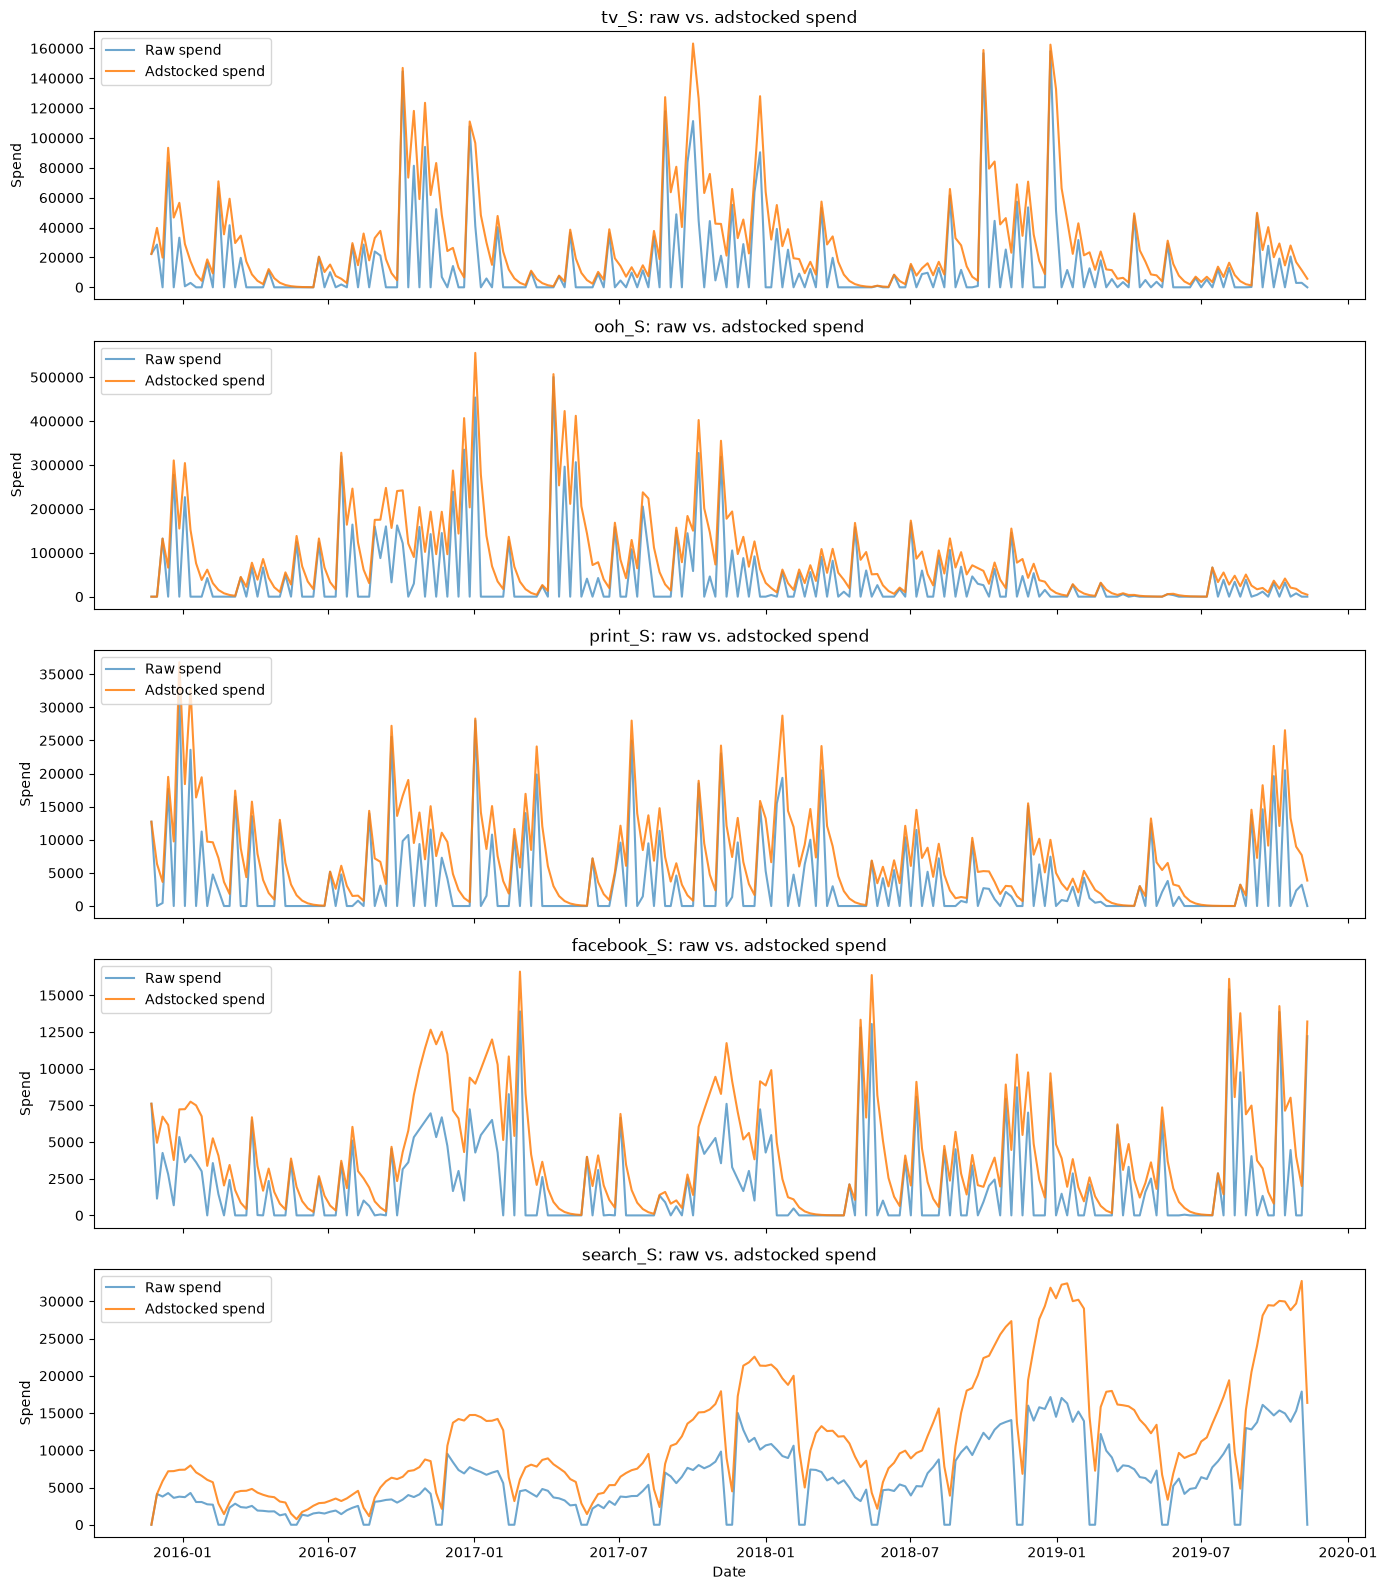

In [11]:
fig, axes = plt.subplots(
    nrows=len(MEDIA_COLS),
    ncols=1,
    figsize=(14, 3.2 * len(MEDIA_COLS)),
    sharex=True,
)

for ax, channel in zip(axes, MEDIA_COLS):
    ax.plot(
        df["DATE"], df[channel],
        label="Raw spend",
        alpha=0.65,
    )
    ax.plot(
        df["DATE"], transformed_df[f"{channel}_adstock"],
        label="Adstocked spend",
        alpha=0.85,
    )

    ax.set_title(f"{channel}: raw vs. adstocked spend")
    ax.set_ylabel("Spend")
    ax.legend(loc="upper left")

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

In [12]:
# Saturated features should be bounded between 0 and 1.
saturated_cols = [f"{channel}_mmm" for channel in MEDIA_COLS]

print("Saturated feature ranges:")
display(transformed_df[saturated_cols].agg(["min", "median", "max"]).round(4))

assert (transformed_df[saturated_cols].to_numpy() >= 0).all()
assert (transformed_df[saturated_cols].to_numpy() <= 1).all()

Saturated feature ranges:


,tv_S_mmm,ooh_S_mmm,print_S_mmm,facebook_S_mmm,search_S_mmm
min,0.0028,0.0000,0.0005,0.0007,0.0000
median,0.5000,0.4958,0.4999,0.5000,0.4991
max,0.9043,0.9108,0.8675,0.8408,0.7737


## Create leakage-aware MMM features

In [13]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
)
from scipy.optimize import lsq_linear

# Keep the same chronological 80/20 split as the baseline.
split_idx = int(len(df) * 0.80)

train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy()

y_train = train_df[TARGET].to_numpy(dtype=float)
y_test = test_df[TARGET].to_numpy(dtype=float)

DECAY_START = 0.5
HILL_SLOPE_START = 1.0

mmm_features = pd.DataFrame({"DATE": df["DATE"]})
mmm_features["revenue"] = df[TARGET]

channel_parameters = {}

for channel in MEDIA_COLS:
    raw_spend = df[channel].to_numpy(dtype=float)

    # Adstock is computed in date order, including history before the split.
    adstocked = geometric_adstock(raw_spend, decay=DECAY_START)

    # Estimate half-saturation using training observations only.
    train_adstock = adstocked[:split_idx]
    positive_train = train_adstock[train_adstock > 0]

    if len(positive_train) == 0:
        raise ValueError(f"No positive training spend for {channel}")

    half_saturation = float(np.median(positive_train))

    saturated = hill_saturation(
        adstocked,
        half_saturation=half_saturation,
        slope=HILL_SLOPE_START,
    )

    feature_name = f"{channel}_mmm"
    mmm_features[feature_name] = saturated

    channel_parameters[channel] = {
        "decay": DECAY_START,
        "slope": HILL_SLOPE_START,
        "half_saturation": half_saturation,
    }

In [14]:
# Use monthly seasonality as a categorical control.
mmm_features["month"] = df["DATE"].dt.month.astype(str)

# Standardize competitor sales using training-period statistics only.
competitor_mean = train_df["competitor_sales_B"].mean()
competitor_std = train_df["competitor_sales_B"].std()

if competitor_std == 0:
    raise ValueError("Competitor sales has zero training-period variation")

mmm_features["competitor_sales_std"] = (
    df["competitor_sales_B"] - competitor_mean
) / competitor_std

# One-hot encode month and retain consistent columns across train/test.
month_dummies = pd.get_dummies(
    mmm_features["month"],
    prefix="month",
    drop_first=True,
    dtype=float,
)

In [15]:
# Assemble the design matrix. Month 1 is the reference category.
design = pd.concat(
    [
        mmm_features[["competitor_sales_std"]],
        month_dummies,
        mmm_features[
            [f"{channel}_mmm" for channel in MEDIA_COLS]
        ],
    ],
    axis=1,
)

In [16]:
# Add intercept.
design.insert(0, "intercept", 1.0)

X_train = design.iloc[:split_idx].to_numpy(dtype=float)
X_test = design.iloc[split_idx:].to_numpy(dtype=float)

feature_names = design.columns.tolist()

print("Training rows:", len(X_train))
print("Holdout rows:", len(X_test))
print("Design matrix columns:", len(feature_names))
print("Channel half-saturation starting values:")

display(
    pd.DataFrame.from_dict(channel_parameters, orient="index")
    .rename_axis("Channel")
    .round(4)
)

assert np.isfinite(X_train).all()
assert np.isfinite(X_test).all()
assert np.isfinite(y_train).all()
assert np.isfinite(y_test).all()

Training rows: 166
Holdout rows: 42
Design matrix columns: 18
Channel half-saturation starting values:


,decay,slope,half_saturation
Channel,,,
tv_S,0.5,1.0,19094.3911
ooh_S,0.5,1.0,71559.9820
print_S,0.5,1.0,6410.5009
facebook_S,0.5,1.0,3445.5238
search_S,0.5,1.0,8069.9394


## Fit the first constrained MMM

In [17]:
# By construction, the final columns correspond to the media features.
media_feature_names = [f"{channel}_mmm" for channel in MEDIA_COLS]
media_indices = [
    feature_names.index(name) for name in media_feature_names
]

# All coefficients are unrestricted initially.
lower_bounds = np.full(X_train.shape[1], -np.inf)
upper_bounds = np.full(X_train.shape[1], np.inf)

# Constrain only media coefficients to be >= 0.
lower_bounds[media_indices] = 0.0

mmm_model = lsq_linear(
    X_train,
    y_train,
    bounds=(lower_bounds, upper_bounds),
    method="trf",
    max_iter=2000,
)

if not mmm_model.success:
    print("Optimizer message:", mmm_model.message)
    raise RuntimeError("MMM optimization did not converge successfully")

mmm_train_pred = X_train @ mmm_model.x
mmm_test_pred = X_test @ mmm_model.x

coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": mmm_model.x,
})

print("MMM fitted successfully.")
print("Optimizer message:", mmm_model.message)

display(coefficients.round(4))

MMM fitted successfully.
Optimizer message: The unconstrained solution is optimal.


,Feature,Coefficient
0,intercept,1.075610e+06
1,competitor_sales_std,5.816393e+05
2,month_10,-7.822891e+04
3,month_11,4.221515e+04
4,month_12,2.133145e+05
5,month_2,7.017832e+04
6,month_3,1.288600e+05
7,month_4,4.234424e+05
8,month_5,5.439177e+05
9,month_6,2.134771e+05


## Evaluate the MMM against the baseline

In [18]:
def calculate_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    revenue_range = np.max(y_true) - np.min(y_true)

    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": rmse,
        "MAPE (%)": mape,
        "NRMSE (range)": (
            rmse / revenue_range if revenue_range > 0 else np.nan
        ),
    }

In [19]:
mmm_train_metrics = calculate_metrics(y_train, mmm_train_pred)
mmm_test_metrics = calculate_metrics(y_test, mmm_test_pred)

mmm_metrics_df = pd.DataFrame({
    "Training": mmm_train_metrics,
    "Holdout": mmm_test_metrics,
})

display(mmm_metrics_df.round(4))

,Training,Holdout
R2,0.8720,0.8238
MAE,156498.1798,196931.1354
RMSE,257339.0006,273916.8369
MAPE (%),9.5366,16.9190
NRMSE (range),0.0830,0.1307


In [20]:
# Compare the holdout results with the baseline results you recorded.
# Enter the actual baseline values from Stage 2 below.
baseline_holdout = {
    "R2": 0.5997,
    "MAE": 351882.6900,
    "RMSE": 412914.7812,
    "MAPE (%)": 30.6075,
    "NRMSE (range)": 0.1970,
}

comparison = pd.DataFrame({
    "Baseline Ridge": baseline_holdout,
    "Constrained MMM": mmm_test_metrics,
})

display(comparison.round(4))

,Baseline Ridge,Constrained MMM
R2,0.5997,0.8238
MAE,351882.6900,196931.1354
RMSE,412914.7812,273916.8369
MAPE (%),30.6075,16.9190
NRMSE (range),0.1970,0.1307


## Plot holdout predictions and residuals

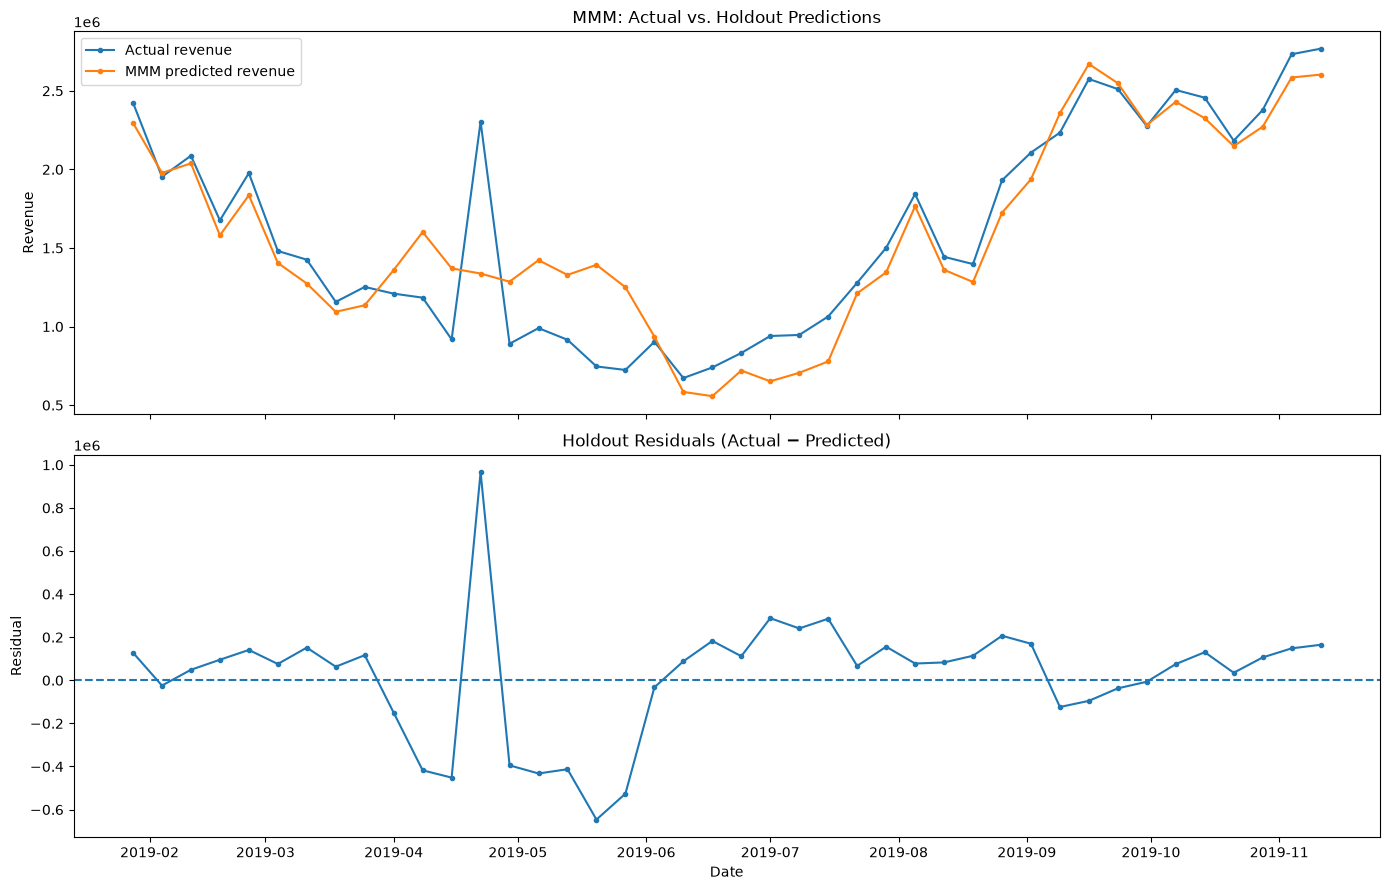

In [21]:
holdout_results = pd.DataFrame({
    "DATE": test_df["DATE"].to_numpy(),
    "Actual_Revenue": y_test,
    "Predicted_Revenue": mmm_test_pred,
})

holdout_results["Residual"] = (
    holdout_results["Actual_Revenue"]
    - holdout_results["Predicted_Revenue"]
)

holdout_results["Absolute_Percentage_Error"] = (
    holdout_results["Residual"].abs()
    / holdout_results["Actual_Revenue"]
    * 100
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

axes[0].plot(
    holdout_results["DATE"],
    holdout_results["Actual_Revenue"],
    label="Actual revenue",
    marker="o",
    markersize=3,
)
axes[0].plot(
    holdout_results["DATE"],
    holdout_results["Predicted_Revenue"],
    label="MMM predicted revenue",
    marker="o",
    markersize=3,
)
axes[0].set_title("MMM: Actual vs. Holdout Predictions")
axes[0].set_ylabel("Revenue")
axes[0].legend()

axes[1].axhline(0, linestyle="--")
axes[1].plot(
    holdout_results["DATE"],
    holdout_results["Residual"],
    marker="o",
    markersize=3,
)
axes[1].set_title("Holdout Residuals (Actual − Predicted)")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()

In [22]:
print("Five largest holdout percentage errors:")
display(
    holdout_results.nlargest(
        5, "Absolute_Percentage_Error"
    ).round(2)
)

print("Mean holdout residual:", round(holdout_results["Residual"].mean(), 2))
print("Holdout residual standard deviation:", round(holdout_results["Residual"].std(), 2))

Five largest holdout percentage errors:


C:\Users\Neel\AppData\Local\Temp\ipykernel_7020\2765680591.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(2)


,DATE,Actual_Revenue,Predicted_Revenue,Residual,Absolute_Percentage_Error
16,2019-05-20,746205.00,1392542.31,-646337.31,86.62
17,2019-05-27,723785.00,1249937.69,-526152.69,72.69
11,2019-04-15,918593.33,1370183.55,-451590.22,49.16
15,2019-05-13,915791.67,1328483.49,-412691.82,45.06
13,2019-04-29,890675.00,1285446.03,-394771.03,44.32


Mean holdout residual: 18250.59
Holdout residual standard deviation: 276621.11


## Check the model's channel coefficient constraints

In [23]:
media_coefficient_check = coefficients[
    coefficients["Feature"].isin(media_feature_names)
].copy()

media_coefficient_check["Non_Negative"] = (
    media_coefficient_check["Coefficient"] >= -1e-8
)

display(media_coefficient_check.round(4))

assert media_coefficient_check["Non_Negative"].all()
print("All media coefficients satisfy the non-negative constraint.")

,Feature,Coefficient,Non_Negative
13,tv_S_mmm,704265.0978,True
14,ooh_S_mmm,56687.2489,True
15,print_S_mmm,252240.9431,True
16,facebook_S_mmm,256060.4398,True
17,search_S_mmm,102314.0391,True


All media coefficients satisfy the non-negative constraint.


## Check event dates and residual patterns

In [38]:
# Attach original event labels and selected control variables.
diagnostics = holdout_results.copy()

diagnostics["events"] = (
    df.iloc[split_idx:]["events"].astype(str).to_numpy()
)
diagnostics["competitor_sales_B"] = (
    df.iloc[split_idx:]["competitor_sales_B"].to_numpy()
)
diagnostics["newsletter"] = (
    df.iloc[split_idx:]["newsletter"].to_numpy()
)

In [39]:
print("Event-labeled weeks in the holdout:")
display(
    diagnostics.loc[
        diagnostics["events"].str.lower().ne("na"),
        [
            "DATE", "events", "Actual_Revenue",
            "Predicted_Revenue", "Residual",
        ],
    ].round(2)
)

print("Largest residuals by absolute magnitude:")
display(
    diagnostics.assign(
        Absolute_Residual=diagnostics["Residual"].abs()
    )
    .nlargest(10, "Absolute_Residual")[
        [
            "DATE", "events", "Actual_Revenue",
            "Predicted_Revenue", "Residual",
        ]
    ]
    .round(2)
)

print(
    "Correlation of residuals with competitor sales:",
    round(
        diagnostics["Residual"].corr(
            diagnostics["competitor_sales_B"]
        ),
        4,
    ),
)

print(
    "Correlation of residuals with newsletter:",
    round(
        diagnostics["Residual"].corr(diagnostics["newsletter"]),
        4,
    ),
)

Event-labeled weeks in the holdout:


C:\Users\Neel\AppData\Local\Temp\ipykernel_7020\1662199924.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,DATE,events,Actual_Revenue,Predicted_Revenue,Residual
12,2019-04-22,event2,2303595.0,1337331.02,966263.98


Largest residuals by absolute magnitude:


C:\Users\Neel\AppData\Local\Temp\ipykernel_7020\1662199924.py:23: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2)


,DATE,events,Actual_Revenue,Predicted_Revenue,Residual
12,2019-04-22,event2,2303595.00,1337331.02,966263.98
16,2019-05-20,na,746205.00,1392542.31,-646337.31
17,2019-05-27,na,723785.00,1249937.69,-526152.69
11,2019-04-15,na,918593.33,1370183.55,-451590.22
14,2019-05-06,na,989913.33,1422331.91,-432418.58
10,2019-04-08,na,1183801.67,1601534.39,-417732.72
15,2019-05-13,na,915791.67,1328483.49,-412691.82
13,2019-04-29,na,890675.00,1285446.03,-394771.03
22,2019-07-01,na,939896.67,651567.07,288329.60
24,2019-07-15,na,1063913.33,778100.35,285812.99


Correlation of residuals with competitor sales: 0.2322
Correlation of residuals with newsletter: -0.1316



### Stage 3: Marketing Mix Modeling

1. Developed a Marketing Mix Model using geometric adstock to capture media carryover and Hill saturation to represent diminishing returns, with monthly indicators and competitor sales as control variables. Media coefficients were constrained to be non-negative.

2. Evaluated the model using a chronological train-test split (166 training observations and 42 holdout observations). The MMM achieved a holdout R² of **0.8238**, MAE of **196,931**, RMSE of **273,917**, and MAPE of **16.92%**, improving on the baseline Ridge model's holdout R² of 0.5997 and MAPE of 30.61%.

3. Investigated holdout residuals and identified substantial errors around April–May 2019, including an underprediction of approximately **966,264** on the event-labeled week of April 22. These findings highlight unexplained temporal variation and the need for caution when interpreting model estimates.


# Estimate channel contributions and revenue-based ROAS proxies

## Calculate modeled channel contributions

In [26]:
# Retrieve fitted coefficients by feature name.
coef_map = dict(zip(feature_names, mmm_model.x))

contribution_df = pd.DataFrame({
    "DATE": df["DATE"],
    "Actual_Revenue": df[TARGET],
})

for channel in MEDIA_COLS:
    feature = f"{channel}_mmm"
    contribution_df[f"{channel}_contribution"] = (
        coef_map[feature] * mmm_features[feature].to_numpy()
    )

contribution_cols = [
    f"{channel}_contribution" for channel in MEDIA_COLS
]

contribution_df["Total_Media_Contribution"] = (
    contribution_df[contribution_cols].sum(axis=1)
)

In [27]:
# These are the non-media terms, including intercept, month indicators,
# and competitor sales. They complete the model's prediction.
non_media_features = [
    name for name in feature_names
    if name not in media_feature_names
]

non_media_indices = [
    feature_names.index(name) for name in non_media_features
]

contribution_df["Non_Media_Component"] = (
    design[non_media_features].to_numpy()
    @ mmm_model.x[non_media_indices]
)

contribution_df["Model_Predicted_Revenue"] = (
    contribution_df["Total_Media_Contribution"]
    + contribution_df["Non_Media_Component"]
)

In [28]:
# Verify decomposition matches model predictions.
max_difference = np.max(
    np.abs(
        contribution_df["Model_Predicted_Revenue"].to_numpy()
        - (design.to_numpy() @ mmm_model.x)
    )
)

print("Maximum decomposition difference:", round(max_difference, 8))
assert np.allclose(
    contribution_df["Model_Predicted_Revenue"].to_numpy(),
    design.to_numpy() @ mmm_model.x,
)

print("Average model-attributed contribution by channel:")
display(
    contribution_df[contribution_cols]
    .mean()
    .sort_values(ascending=False)
    .rename("Average Weekly Contribution")
    .to_frame()
    .round(2)
)

Maximum decomposition difference: 0.0
Average model-attributed contribution by channel:


,Average Weekly Contribution
tv_S_contribution,327298.69
facebook_S_contribution,113307.07
print_S_contribution,108280.72
search_S_contribution,53976.65
ooh_S_contribution,23507.99


## Summarize spend, contribution, and ROAS proxy

In [29]:
channel_summary = []

for channel in MEDIA_COLS:
    total_spend = df[channel].sum()
    total_contribution = contribution_df[
        f"{channel}_contribution"
    ].sum()

    channel_summary.append({
        "Channel": channel,
        "Total_Spend": total_spend,
        "Total_Model_Contribution": total_contribution,
        "Contribution_Share (%)": (
            total_contribution
            / contribution_df["Total_Media_Contribution"].sum()
            * 100
            if contribution_df["Total_Media_Contribution"].sum() > 0
            else np.nan
        ),
        "Revenue_per_Spend_Proxy": (
            total_contribution / total_spend
            if total_spend > 0
            else np.nan
        ),
    })

In [30]:
channel_summary_df = (
    pd.DataFrame(channel_summary)
    .sort_values("Revenue_per_Spend_Proxy", ascending=False)
    .reset_index(drop=True)
)

display(channel_summary_df.round(3))

,Channel,Total_Spend,Total_Model_Contribution,Contribution_Share (%),Revenue_per_Spend_Proxy
0,facebook_S,446296.828,2.356787e+07,18.089,52.808
1,print_S,775555.511,2.252239e+07,17.287,29.040
2,tv_S,3087487.773,6.807813e+07,52.253,22.050
3,search_S,1230426.667,1.122714e+07,8.617,9.125
4,ooh_S,8989331.733,4.889662e+06,3.753,0.544


## Visualize contribution by channel

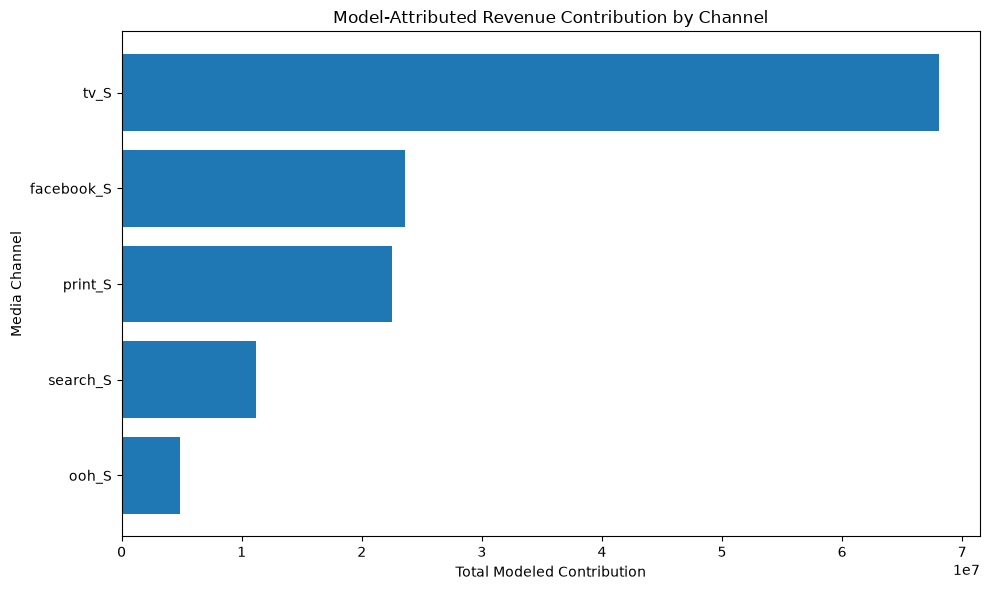

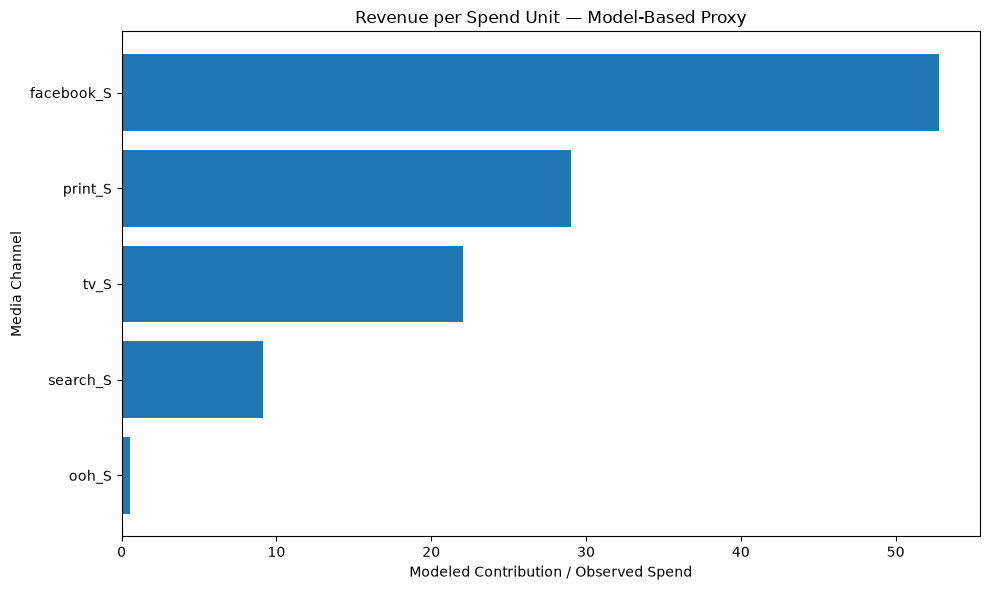

In [31]:
plot_summary = channel_summary_df.sort_values(
    "Total_Model_Contribution", ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    plot_summary["Channel"],
    plot_summary["Total_Model_Contribution"],
)
plt.title("Model-Attributed Revenue Contribution by Channel")
plt.xlabel("Total Modeled Contribution")
plt.ylabel("Media Channel")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
roas_plot = channel_summary_df.sort_values(
    "Revenue_per_Spend_Proxy", ascending=True
)

plt.barh(
    roas_plot["Channel"],
    roas_plot["Revenue_per_Spend_Proxy"],
)
plt.title("Revenue per Spend Unit — Model-Based Proxy")
plt.xlabel("Modeled Contribution / Observed Spend")
plt.ylabel("Media Channel")
plt.tight_layout()
plt.show()

## Generate response curves

In [32]:
response_curves = {}
response_summary = []

for channel in MEDIA_COLS:
    params = channel_parameters[channel]
    decay = params["decay"]
    slope = params["slope"]
    half_saturation = params["half_saturation"]

    # Use a grid spanning zero to the 95th percentile of observed spend.
    max_weekly_spend = float(df[channel].quantile(0.95))
    spend_grid = np.linspace(0, max_weekly_spend, 150)

    # Under constant weekly spend, geometric adstock approaches:
    # steady_state_adstock = weekly_spend / (1 - decay)
    steady_state_adstock = spend_grid / (1 - decay)

    saturated_response = hill_saturation(
        steady_state_adstock,
        half_saturation=half_saturation,
        slope=slope,
    )

    # Modeled channel contribution at steady state.
    contribution = coef_map[f"{channel}_mmm"] * saturated_response

    response_curves[channel] = pd.DataFrame({
        "Weekly_Spend": spend_grid,
        "Steady_State_Adstock": steady_state_adstock,
        "Saturated_Response": saturated_response,
        "Modeled_Contribution": contribution,
    })

    response_summary.append({
        "Channel": channel,
        "Spend_at_95th_percentile": max_weekly_spend,
        "Contribution_at_zero_spend": contribution[0],
        "Contribution_at_max_grid": contribution[-1],
        "Contribution_gain_over_grid": contribution[-1] - contribution[0],
    })

response_summary_df = pd.DataFrame(response_summary)
display(response_summary_df.round(2))

,Channel,Spend_at_95th_percentile,Contribution_at_zero_spend,Contribution_at_max_grid,Contribution_gain_over_grid
0,tv_S,76099.83,0.0,625759.67,625759.67
1,ooh_S,219293.84,0.0,48735.55,48735.55
2,print_S,19052.55,0.0,215916.81,215916.81
3,facebook_S,8028.00,0.0,210819.77,210819.77
4,search_S,15260.67,0.0,80918.84,80918.84


## Plotting the curves

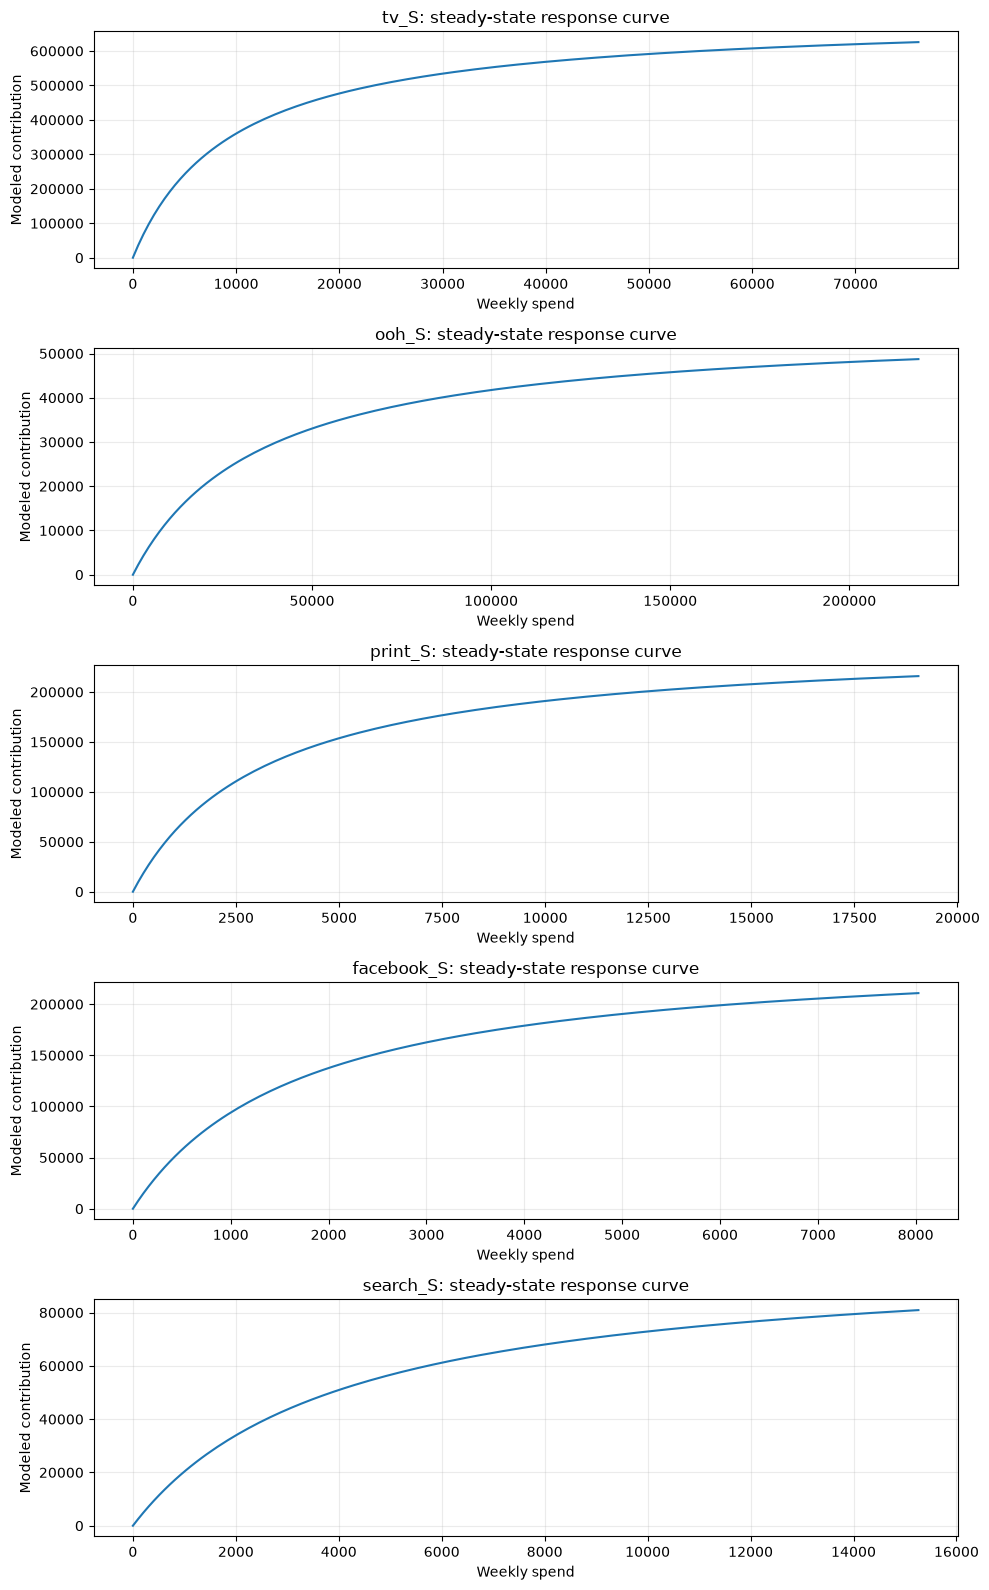

In [33]:
fig, axes = plt.subplots(
    nrows=len(MEDIA_COLS),
    ncols=1,
    figsize=(10, 3.2 * len(MEDIA_COLS)),
)

for ax, channel in zip(axes, MEDIA_COLS):
    curve = response_curves[channel]

    ax.plot(
        curve["Weekly_Spend"],
        curve["Modeled_Contribution"],
    )
    ax.set_title(f"{channel}: steady-state response curve")
    ax.set_xlabel("Weekly spend")
    ax.set_ylabel("Modeled contribution")
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Estimate marginal response near typical spend

In [ ]:
marginal_summary = []

for channel in MEDIA_COLS:
    curve = response_curves[channel]

    # Exclude zero-spend weeks to find a representative active spend level.
    positive_spend = df.loc[df[channel] > 0, channel]

    if positive_spend.empty:
        print(f"Skipping {channel}: no positive-spend weeks.")
        continue

    reference_spend = float(positive_spend.median())

    spend_grid = curve["Weekly_Spend"].to_numpy()
    contribution_grid = curve["Modeled_Contribution"].to_numpy()

    # Calculate the numerical slope of the response curve.
    marginal_grid = np.gradient(contribution_grid, spend_grid)

    # Interpolate the curve and its slope at the reference spend.
    reference_contribution = float(
        np.interp(reference_spend, spend_grid, contribution_grid)
    )
    local_marginal_response = float(
        np.interp(reference_spend, spend_grid, marginal_grid)
    )

    marginal_summary.append({
        "Channel": channel,
        "Median_Positive_Weekly_Spend": reference_spend,
        "Modeled_Contribution_at_Reference_Spend": reference_contribution,
        "Local_Marginal_Response": local_marginal_response,
    })


In [37]:
marginal_summary_df = (
    pd.DataFrame(marginal_summary)
    .sort_values("Local_Marginal_Response", ascending=False)
    .reset_index(drop=True)
)

display(marginal_summary_df.round(4))

,Channel,Median_Positive_Weekly_Spend,Modeled_Contribution_at_Reference_Spend,Local_Marginal_Response
0,facebook_S,3673.9308,174318.1814,15.1487
1,print_S,7174.7111,174349.7817,7.5054
2,tv_S,21205.4267,485609.9263,7.1131
3,search_S,6053.3333,61391.6029,4.0569
4,ooh_S,66413.8667,36839.5314,0.1943



### Stage 4: Contribution Analysis and Response Curves

1. Decomposed fitted model predictions into channel-level contributions and non-media components, verifying that the reconstructed predictions matched the model predictions exactly. TV had the largest attributed contribution at approximately **68.08M (52.25%)**, followed by Facebook, Print, Search, and OOH.

2. Calculated revenue-per-spend proxies from modeled contribution and observed spend. Facebook had the highest estimated proxy at approximately **52.81**, followed by Print (29.04), TV (22.05), Search (9.13), and OOH (0.54). These are model-based descriptive estimates, not validated causal ROAS.

3. Constructed steady-state response curves showing diminishing returns and estimated local marginal response at each channel's median positive spend. Facebook had the highest estimated local marginal response (**15.15**), followed by Print (7.51), TV (7.11), Search (4.06), and OOH (0.19). These estimates are conditional on the model's assumptions and will inform but not dictate the budget optimization stage.
